# Tune SEI densities using the first charge cycle

**Context**: This notebook sweeps the SEI **densities** (`rho_EC` and `rho_VC`)
using only the **first charge cycle** of formation (`include_flag=0`).  The
SEI **diffusivities** (`D_LEDC`, `D_LVDC`) are held fixed at their
previously-tuned values.

This combines the structure of two earlier notebooks:

* **`2026_04_16_first_charge_dsei_sweep`** — first-charge-only convention:
  `expt2` for "base", voltage RMSE range starting at **2.0 V**, and
  **smoothed** expansion curves (`daq_strain_smoothed`) to remove the
  early-time kink artefact.
* **`2026_04_26_density_sweep`** — density-sweep configuration: linear
  35×36 grid in (`rho_EC`, `rho_VC`) with fixed `D_LEDC = 4.44e-20` and
  `D_LVDC = 1.3e-17` (m^2/s).

The first charge cycle is where the majority of the LVDC reaction occurs,
making it the most sensitive window for identifying density parameters that
control the LVDC-driven kinetics.  Restricting to `include_flag=0` makes the
sweep substantially faster than the full-protocol density sweep.

Andrew Weng

In [18]:
import os, sys

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('../')
    sys.path.insert(0, 'src/')

from src import cellsim as cellsim

from scipy.interpolate import interp1d

import pickle
import numpy as np
from matplotlib import pyplot as plt
from src import plotter as plotter
from src import ioutils as ioutils
from src import simutils as simutils

%load_ext autoreload
%matplotlib inline

plotter.initialize(plt)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load the experimental data

In [19]:
# Load the experimental data
expt1, _ = ioutils.fetch_experimental_data(152064, 600)
expt2, _ = ioutils.fetch_experimental_data(152074, 600)
expt3, _ = ioutils.fetch_experimental_data(152071, 600)
expt4, _ = ioutils.fetch_experimental_data(152098, 600)


dt_data_interp = 5.0
t_interp1, i_interp1 = simutils.interpolate_raw_data(expt1['arbin_time'], expt1['arbin_current'], dt_data_interp)
t_interp2, i_interp2 = simutils.interpolate_raw_data(expt2['arbin_time'], expt2['arbin_current'], dt_data_interp)
t_interp3, i_interp3 = simutils.interpolate_raw_data(expt3['arbin_time'], expt3['arbin_current'], dt_data_interp)
t_interp4, i_interp4 = simutils.interpolate_raw_data(expt4['arbin_time'], expt4['arbin_current'], dt_data_interp)

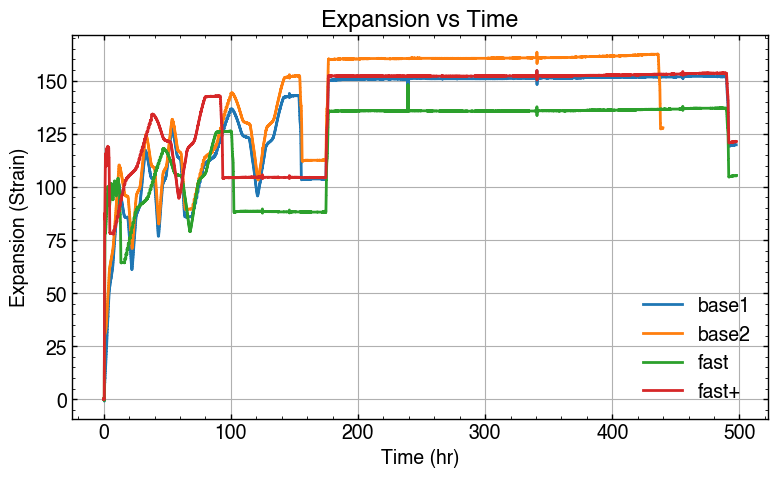

In [20]:
plt.figure(figsize=(8,5))
plt.plot(np.array(expt1['daq_time'])/3600, expt1['daq_strain'], label='base1')
plt.plot(np.array(expt2['daq_time'])/3600, expt2['daq_strain'], label='base2')
plt.plot(np.array(expt3['daq_time'])/3600, expt3['daq_strain'], label='fast')
plt.plot(np.array(expt4['daq_time'])/3600, expt4['daq_strain'], label='fast+')
plt.xlabel('Time (hr)')
plt.ylabel('Expansion (Strain)')
plt.title('Expansion vs Time')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Define affected regions for each dataset
# Format: (expt, label, t_start, t_end)
kink_regions = [
    (expt1, 'Base 1', 0.5, 0.75),
    (expt2, 'Base 2', 0.5, 0.85),
    (expt3, 'Fast', 0.5, 0.6),
    (expt4, 'Fast+', 0.5, 0.55),
]

# Apply smoothing to each dataset
smoothed_strains = {}
for expt, label, t_start, t_end in kink_regions:
    daq_time = np.array(expt['daq_time'])
    daq_strain = np.array(expt['daq_strain'])

    # Convert to hours from zero
    daq_time_hours = (daq_time - daq_time[0]) / 3600.0

    # Apply smoothing
    strain_smoothed = ioutils.smooth_kink_region(daq_time_hours, daq_strain, t_start, t_end)
    smoothed_strains[label] = {
        'time_hours': daq_time_hours,
        'original': daq_strain,
        'smoothed': strain_smoothed,
        't_start': t_start,
        't_end': t_end,
    }

expt1['daq_strain_smoothed'] = smoothed_strains['Base 1']['smoothed']
expt2['daq_strain_smoothed'] = smoothed_strains['Base 2']['smoothed']
expt3['daq_strain_smoothed'] = smoothed_strains['Fast']['smoothed']
expt4['daq_strain_smoothed'] = smoothed_strains['Fast+']['smoothed']

# Sweep densities (first charge cycle only)

In [22]:
# Tuning based on voltage
d_ec_opt1 = 6.66e-20
d_ec_opt2 = 6.66e-20
d_ec_opt3 = 6.66e-20
d_vc_opt1 = 1.22e-18
d_vc_opt2 = 1.22e-18
d_vc_opt3 = 1.22e-18

nn = 55

rho_ec_vec = np.linspace(0.5, 4, nn)
rho_vc_vec = np.linspace(0.5, 4, nn + 1)

shape = (len(rho_ec_vec), len(rho_vc_vec))
_mat_names = [
    'rmse1_e_mat', 'rmse1_v_mat', 'rmse2_e_mat', 'rmse2_v_mat', 'rmse3_e_mat', 'rmse3_v_mat',
    'qsei1_mat', 'qsei2_mat', 'qsei3_mat', 'qsei1_vc_mat', 'qsei2_vc_mat', 'qsei3_vc_mat',
    'expan1_mat', 'expan2_mat', 'expan3_mat',
    'resistance1_mat', 'resistance2_mat', 'resistance3_mat',
]
for _name in _mat_names:
    globals()[_name] = np.zeros(shape)

count = 1

for i, rho_ec in enumerate(rho_ec_vec):
    for j, rho_vc in enumerate(rho_vc_vec):

        print(f'Running rho_EC = {rho_ec:.2e} | rho_VC = {rho_vc:.2e} ({count} of {nn*(nn+1)})')
        count += 1

        try:
            df_sim1 = simutils.run_sim('base',  d_ec_opt1, d_vc_opt1, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=0)
            df_sim2 = simutils.run_sim('fast',  d_ec_opt2, d_vc_opt2, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=0)
            df_sim3 = simutils.run_sim('fast+', d_ec_opt3, d_vc_opt3, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=0)
        except:
            print('ERROR')
            continue

        # Extract the qsei values:
        qsei1_mat[i, j] = df_sim1['q_sei'].iloc[-1]
        qsei2_mat[i, j] = df_sim2['q_sei'].iloc[-1]
        qsei3_mat[i, j] = df_sim3['q_sei'].iloc[-1]

        qsei1_vc_mat[i, j] = df_sim1['q_sei2'].iloc[-1]
        qsei2_vc_mat[i, j] = df_sim2['q_sei2'].iloc[-1]
        qsei3_vc_mat[i, j] = df_sim3['q_sei2'].iloc[-1]

        # Extract the expansion values:
        expan1_mat[i, j] = df_sim1['expansion'].iloc[-1]
        expan2_mat[i, j] = df_sim2['expansion'].iloc[-1]
        expan3_mat[i, j] = df_sim3['expansion'].iloc[-1]

        # Extract the resistance values:
        resistance1_mat[i, j] = df_sim1['R_sei'].iloc[-1]
        resistance2_mat[i, j] = df_sim2['R_sei'].iloc[-1]
        resistance3_mat[i, j] = df_sim3['R_sei'].iloc[-1]

        # First-charge convention: expt2 for base, voltage RMSE from 2.0 V, smoothed strain
        rmse1_v, _, _ = simutils.calculate_rmse(expt1['arbin_time'], expt1['arbin_voltage'],         df_sim1['t'], df_sim1['vt'],            ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse1_e, _, _ = simutils.calculate_rmse(expt1['daq_time'],   expt1['daq_strain_smoothed'],   df_sim1['t'], df_sim1['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse2_v, _, _ = simutils.calculate_rmse(expt3['arbin_time'], expt3['arbin_voltage'],         df_sim2['t'], df_sim2['vt'],            ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse2_e, _, _ = simutils.calculate_rmse(expt3['daq_time'],   expt3['daq_strain_smoothed'],   df_sim2['t'], df_sim2['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse3_v, _, _ = simutils.calculate_rmse(expt4['arbin_time'], expt4['arbin_voltage'],         df_sim3['t'], df_sim3['vt'],            ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse3_e, _, _ = simutils.calculate_rmse(expt4['daq_time'],   expt4['daq_strain_smoothed'],   df_sim3['t'], df_sim3['expansion']*1e6, ignore_time_range=(0,30*60))

        rmse1_e_mat[i, j] = rmse1_e
        rmse1_v_mat[i, j] = rmse1_v
        rmse2_e_mat[i, j] = rmse2_e
        rmse2_v_mat[i, j] = rmse2_v
        rmse3_e_mat[i, j] = rmse3_e
        rmse3_v_mat[i, j] = rmse3_v

# Replace zeros with np.nan (failed runs)
for _name in _mat_names:
    globals()[_name] = np.where(globals()[_name] == 0, np.nan, globals()[_name])

combined_rmse1 = rmse1_e_mat/np.nanmax(rmse1_e_mat) + rmse1_v_mat/np.nanmax(rmse1_v_mat)
combined_rmse2 = rmse2_e_mat/np.nanmax(rmse2_e_mat) + rmse2_v_mat/np.nanmax(rmse2_v_mat)
combined_rmse3 = rmse3_e_mat/np.nanmax(rmse3_e_mat) + rmse3_v_mat/np.nanmax(rmse3_v_mat)

# Compute error metrics based on cell capacity and resistance
Rother = 0.0215 - 0.09197987391102377  # gets the R error to 0 for the base case
Rmeas1 = 0.0215
Rmeas2 = 0.0178
Rmeas3 = 0.0166
Q_max  = 2.87
Q_meas = 2.54

# Capacity error
eq1_mat = (qsei1_mat - (Q_max - Q_meas))**2
eq2_mat = (qsei2_mat - (Q_max - Q_meas))**2
eq3_mat = (qsei3_mat - (Q_max - Q_meas))**2

# Resistance error
er1_mat = ((resistance1_mat + Rother) - Rmeas1)**2
er2_mat = ((resistance2_mat + Rother) - Rmeas2)**2
er3_mat = ((resistance3_mat + Rother) - Rmeas3)**2

# Combined capacity and resistance error
ec1_mat = (eq1_mat / np.nanmax(eq1_mat)) + (er1_mat / np.nanmax(er1_mat))
ec2_mat = (eq2_mat / np.nanmax(eq2_mat)) + (er2_mat / np.nanmax(er2_mat))
ec3_mat = (eq3_mat / np.nanmax(eq3_mat)) + (er3_mat / np.nanmax(er3_mat))

Running rho_EC = 5.00e-01 | rho_VC = 5.00e-01 (1 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 5.64e-01 (2 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 6.27e-01 (3 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 6.91e-01 (4 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 7.55e-01 (5 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 8.18e-01 (6 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 8.82e-01 (7 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 9.45e-01 (8 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.01e+00 (9 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.07e+00 (10 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.14e+00 (11 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.20e+00 (12 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.26e+00 (13 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.33e+00 (14 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.39e+00 (15 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.45e+00 (16 of 3080)
Running rho_EC = 5.00e-01 | rho_VC = 1.52e+00 (17 of 3080)
Runnin

In [25]:
%autoreload 2

variables_to_pickle = {
    'rmse1_e_mat': rmse1_e_mat,
    'rmse1_v_mat': rmse1_v_mat,
    'rmse2_e_mat': rmse2_e_mat,
    'rmse2_v_mat': rmse2_v_mat,
    'rmse3_e_mat': rmse3_e_mat,
    'rmse3_v_mat': rmse3_v_mat,
    'qsei1_mat': qsei1_mat,
    'qsei2_mat': qsei2_mat,
    'qsei3_mat': qsei3_mat,
    'qsei1_vc_mat': qsei1_vc_mat,
    'qsei2_vc_mat': qsei2_vc_mat,
    'qsei3_vc_mat': qsei3_vc_mat,
    'expan1_mat': expan1_mat,
    'expan2_mat': expan2_mat,
    'expan3_mat': expan3_mat,
    'resistance1_mat': resistance1_mat,
    'resistance2_mat': resistance2_mat,
    'resistance3_mat': resistance3_mat,
    'combined_rmse1': combined_rmse1,
    'combined_rmse2': combined_rmse2,
    'combined_rmse3': combined_rmse3,
    'eq1_mat': eq1_mat,
    'eq2_mat': eq2_mat,
    'eq3_mat': eq3_mat,
    'er1_mat': er1_mat,
    'er2_mat': er2_mat,
    'er3_mat': er3_mat,
    'ec1_mat': ec1_mat,
    'ec2_mat': ec2_mat,
    'ec3_mat': ec3_mat,
}

with open('outputs/simulation_results_first_charge_density_20260429.pkl', 'wb') as f:
    pickle.dump(variables_to_pickle, f)

# Visualize results

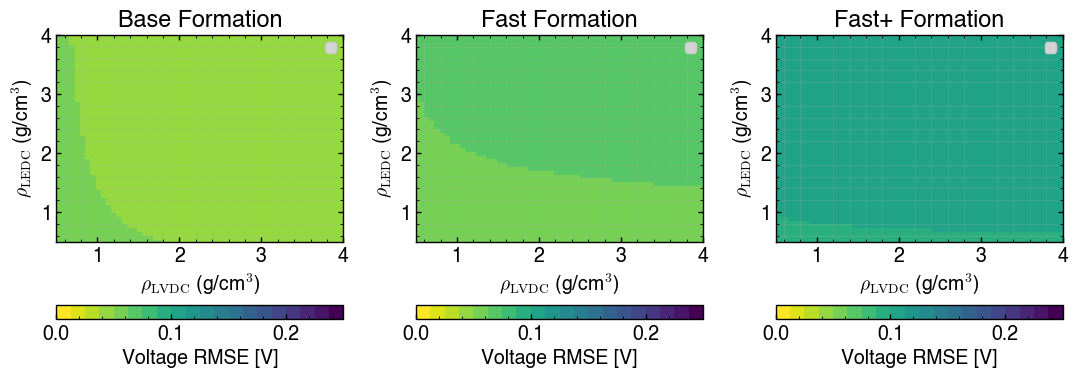

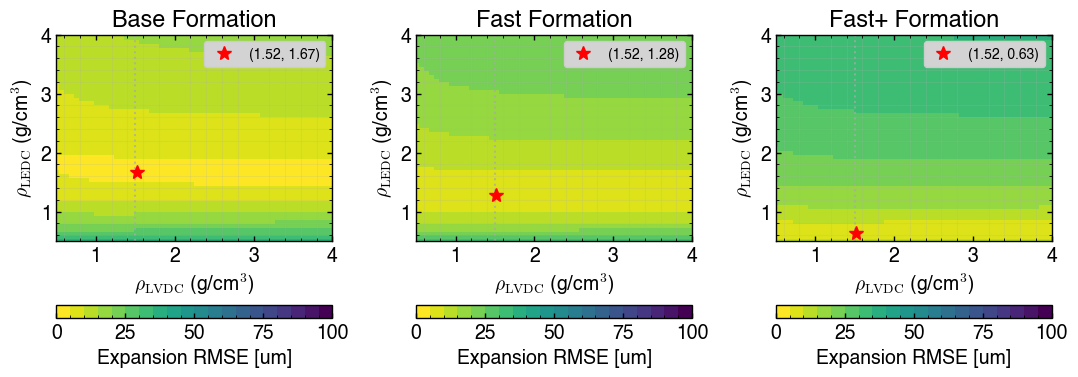

In [27]:
%matplotlib inline
with open('outputs/simulation_results_first_charge_density_20260429.pkl', 'rb') as f:
    sim_results = pickle.load(f)

nn = 55
rho_ec_vec = np.linspace(0.5, 4, nn)
rho_vc_vec = np.linspace(0.5, 4, nn + 1)

simutils.plot_heatmaps_rho(
    rho_ec_vec, rho_vc_vec,
    sim_results['rmse1_v_mat'], sim_results['rmse2_v_mat'], sim_results['rmse3_v_mat'],
    'Voltage RMSE [V]',
    zmin=0.0, zmax=0.25,
    tosave=True,
    savename='outputs/figures/heatmap_rho_rmse_v_form_firstcyc.svg',
    to_annotate=False,
)

simutils.plot_heatmaps_rho(
    rho_ec_vec, rho_vc_vec,
    sim_results['rmse1_e_mat'], sim_results['rmse2_e_mat'], sim_results['rmse3_e_mat'],
    'Expansion RMSE [um]',
    zmin=0, zmax=100,
    tosave=True,
    savename='outputs/figures/heatmap_rho_rmse_e_form_firstcyc.svg',
    to_annotate=True,
)